<a href="https://colab.research.google.com/github/vinudi20251178-ux/Telco_churn_ml_cw/blob/main/notebooks/Telco_Churn_ml_cw.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Imports and Data Loading

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
path = '/content/drive/MyDrive/Telco-Customer-Churn.csv'
df = pd.read_csv(path)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
df = pd.read_csv(path)
df.head(20)
df.shape
df.info()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [ ]:
df['TotalCharges']=pd.to_numeric(df['TotalCharges'], errors='coerce')
df.isnull().sum()
df[df['TotalCharges'].isnull()]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


TotalCharges were stored as a text(object) rather than anumeric data type because 11 entries were blank strings which isnull() not detected as missing. After converting the column to numeric, these 11 entries appeared as NaN.

Inspecting these rows showed that all of them have tenure = 0 and Churn = No. These are newly registered customers who have not yet completed a billing cycle, so no charges have been recorded. The values are therefore not randomly missing; they are structurally missing for a known reason.

Since a customer with zero months of tenure has accumulated zero total charges, the missing values were filled with 0 rather than dropping the rows. This retains all customer records and reflects the true value, with negligible effect on the dataset given how few rows are affected.


In [ ]:
df['TotalCharges']=df['TotalCharges'].fillna(0)
df['TotalCharges'].dtype
df['TotalCharges'].isnull().sum()


np.int64(0)

In [ ]:
df.duplicated().sum() # Check for duplicate rows and duplicate customer IDs
df.duplicated(subset=['customerID']).sum()

np.int64(0)

In [ ]:
for col in df.select_dtypes(include='object').columns:## Print value counts for each categorical (text) column, skipping customerID since every value is unique
    if col=='customerID':
       continue
    print(df[col].value_counts())

gender
Male      3555
Female    3488
Name: count, dtype: int64
Partner
No     3641
Yes    3402
Name: count, dtype: int64
Dependents
No     4933
Yes    2110
Name: count, dtype: int64
PhoneService
Yes    6361
No      682
Name: count, dtype: int64
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64
OnlineBackup
No                     3088
Yes                    2429
No internet service    1526
Name: count, dtype: int64
DeviceProtection
No                     3095
Yes                    2422
No internet service    1526
Name: count, dtype: int64
TechSupport
No                     3473
Yes                    2044
No internet service    1526
Name: count, dtype: int64
StreamingTV
No                     2810
Y

In [ ]:
churn_persentages=df['Churn'].value_counts(normalize=True)*100 #gives as a float normalize=true
churn_persentages

,proportion
Churn,
No,73.463013
Yes,26.536987


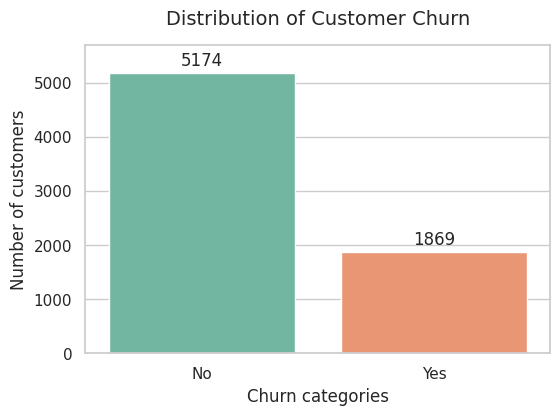

In [ ]:
sb.set_theme(style="whitegrid")
plt.figure(figsize=(6,4))
chart = sb.countplot(data=df, x='Churn', hue='Churn', palette='Set2', legend=False)

for container in chart.containers:
    chart.bar_label(container,fontsize=12,padding=3)
plt.ylim(0, df['Churn'].value_counts().max() * 1.1)


plt.title('Distribution of Customer Churn',fontsize=14,pad=15)
plt.xlabel('Churn categories',fontsize=12)
plt.ylabel('Number of customers',fontsize=12)
plt.show()


The data set contains 7043 customers, of which 5174(73.5%) did not churn and 1869(26.5%) churned. This shows that the target variable is moderately balanced, as the number of customers who did not churn is almost three times higher than the number of customers who churned.

This is important because if the model predicts that all customers will not churn, it can still achieve 73.5% accuracy without identifying any customers who leave the company. Therefore, accuracy alone may not be a reliable way to evaluate the model's performance.

In [ ]:
numeric_cols = ['tenure','MonthlyCharges','TotalCharges']
df[numeric_cols].describe()

,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.350000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


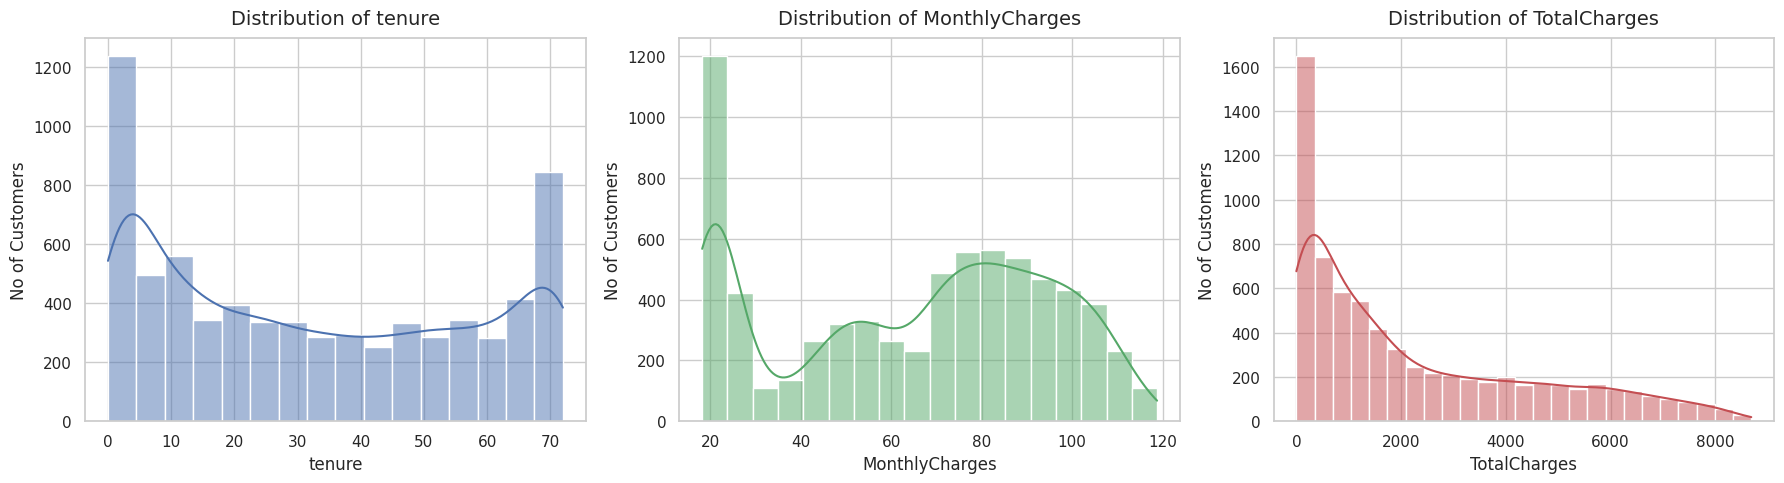

In [ ]:
sb.set_theme(style="whitegrid")

fig,axes=plt.subplots(nrows=1, ncols=3, figsize=(18,5))
cols_of_plot=['tenure','MonthlyCharges','TotalCharges']
colors = ['#4c72b0', '#55a868', '#c44e52']

for i,col in enumerate(cols_of_plot):
  sb.histplot(
      data=df,
      x=col,
      kde=True,
      color=colors[i],
      ax=axes[i])

  axes[i].set_title(f'Distribution of {col}', fontsize=14, pad=10)
  axes[i].set_xlabel(col, fontsize=12)
  axes[i].set_ylabel('No of Customers', fontsize=12)


plt.tight_layout()
plt.show()





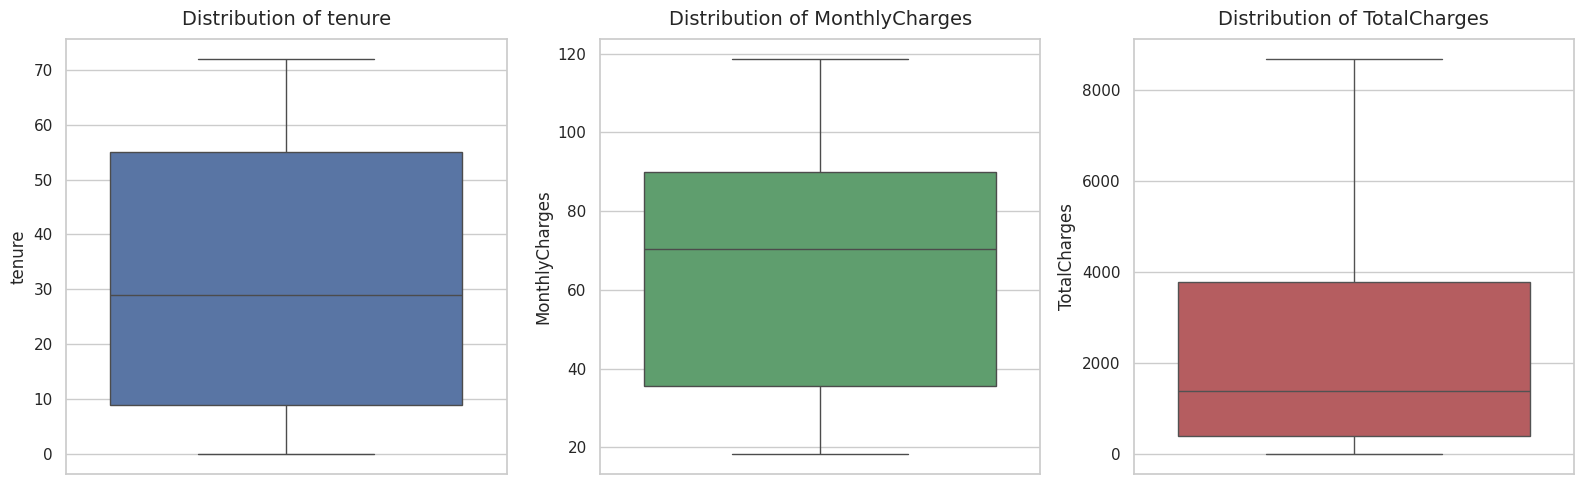

In [ ]:
sb.set_theme(style="whitegrid")

fig,axes=plt.subplots(nrows=1, ncols=3, figsize=(16,5))
cols_of_plot=['tenure','MonthlyCharges','TotalCharges']
colors = ['#4c72b0', '#55a868', '#c44e52']

for i, col in enumerate(cols_of_plot):
    sb.boxplot(
        data=df,
        y=col,
        color=colors[i],
        ax=axes[i],
        flierprops={"markerfacecolor": "red", "markeredgecolor": "red", "markersize": 5}
    )

    axes[i].set_title(f'Distribution of {col}', fontsize=14, pad=10)
    axes[i].set_ylabel(col, fontsize=12)

plt.tight_layout()
plt.show()


 Tenure ranges from 0 to 72 months and has a U-shaped distribution. Many customers are either very new or have stayed for a long time, with fewer in between.

 Monthly charges range from about 18 to 119. There is a large group of customers paying low amounts, and a broader group paying much higher amounts.

 Total charges are right-skewed. Most customers have relatively low totals, while a smaller number have very high ones.

The box plots show no outliers in any of the three features, so no values need to be removed.




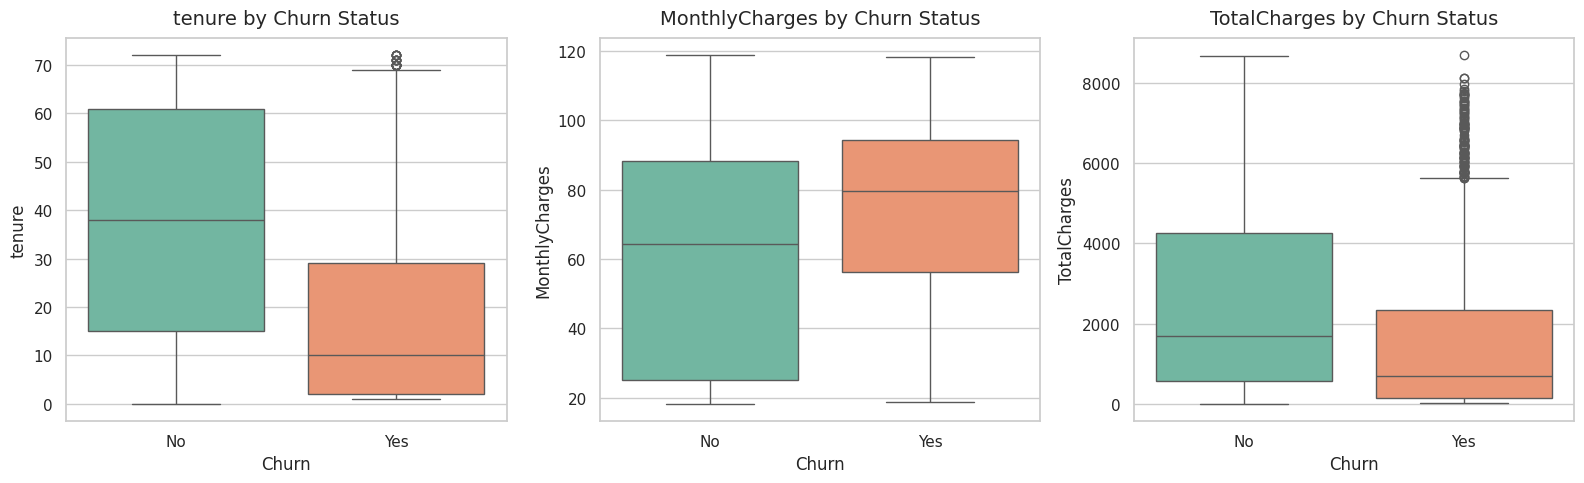

In [ ]:
sb.set_theme(style="whitegrid")

fig,axes=plt.subplots(nrows=1, ncols=3, figsize=(16,5))
cols_of_plot=['tenure','MonthlyCharges','TotalCharges']
colors = ['#4c72b0', '#55a868', '#c44e52']

for i, col in enumerate(cols_of_plot):
    sb.boxplot(
        data=df,
        x='Churn',
        y=col,
        hue='Churn',
        palette='Set2',
        legend=False,
        ax=axes[i]
    )
    axes[i].set_title(f'{col} by Churn Status', fontsize=14, pad=10)
    axes[i].set_xlabel('Churn', fontsize=12)
    axes[i].set_ylabel(col, fontsize=12)


plt.tight_layout()
plt.show()


 Customers who churned have noticeably shorter tenure than those who stayed. Churn is concentrated among newer customers.

 Customers who churned tend to pay higher monthly charges than those who stayed.

 Customers who churned have lower total charges. This is probably because they left earlier and had less time to build up charges.

 The high values flagged as outliers in the churn group are genuine customers, not errors.


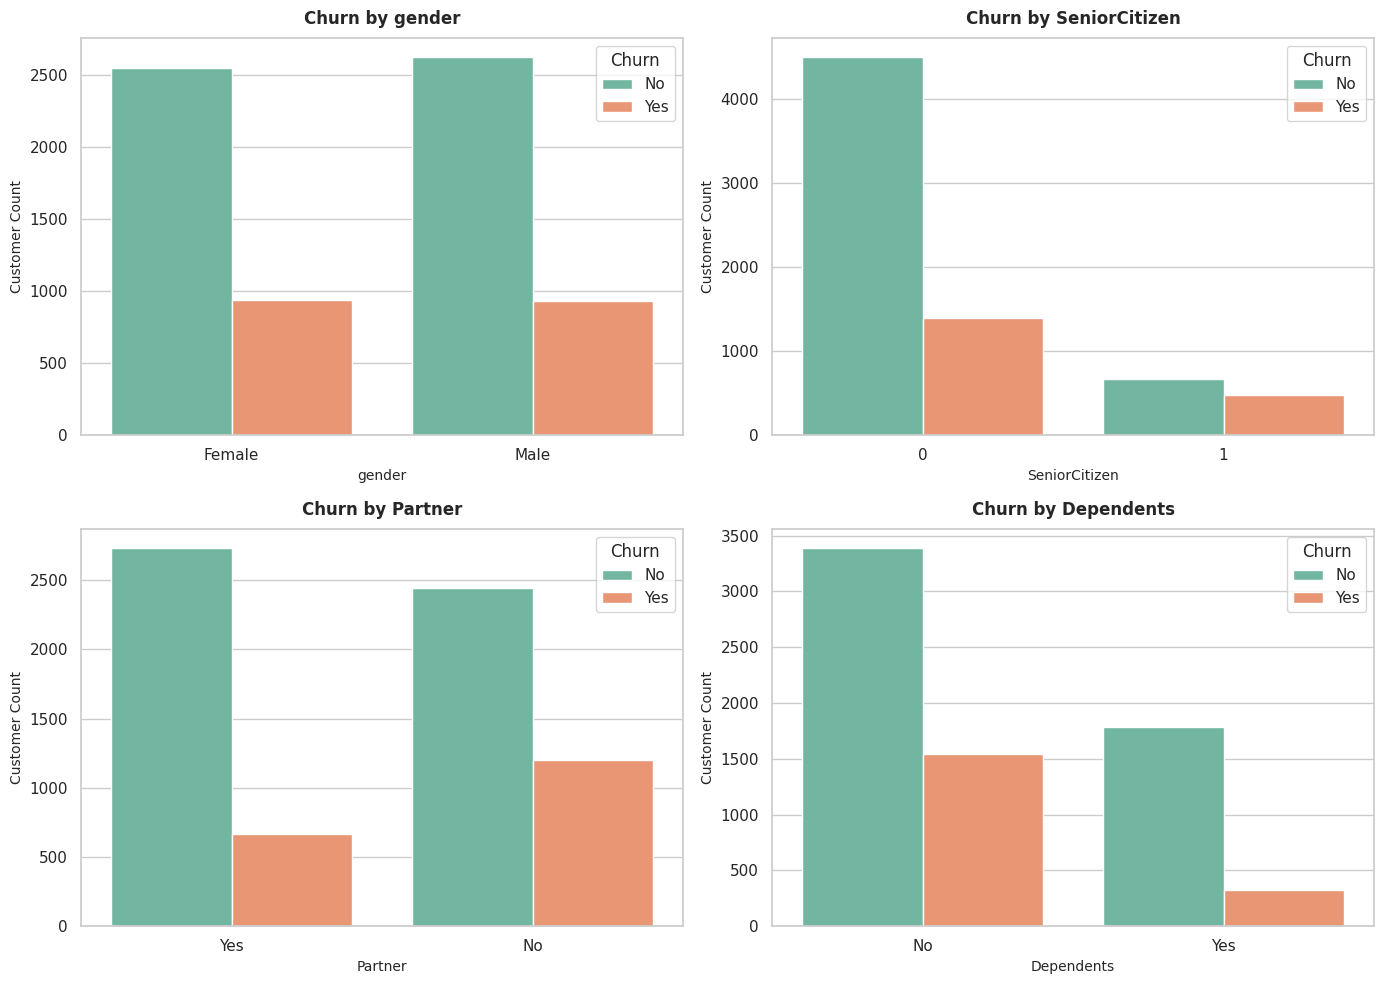

In [ ]:
demo_cols = ['gender', 'SeniorCitizen', 'Partner', 'Dependents']


fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(demo_cols):
    sb.countplot(data=df, x=col, hue='Churn', palette='Set2', ax=axes[i])
    axes[i].set_title(f'Churn by {col}', fontsize=12, fontweight='bold', pad=10)
    axes[i].set_xlabel(col, fontsize=10)
    axes[i].set_ylabel('Customer Count', fontsize=10)

plt.tight_layout()
plt.show()

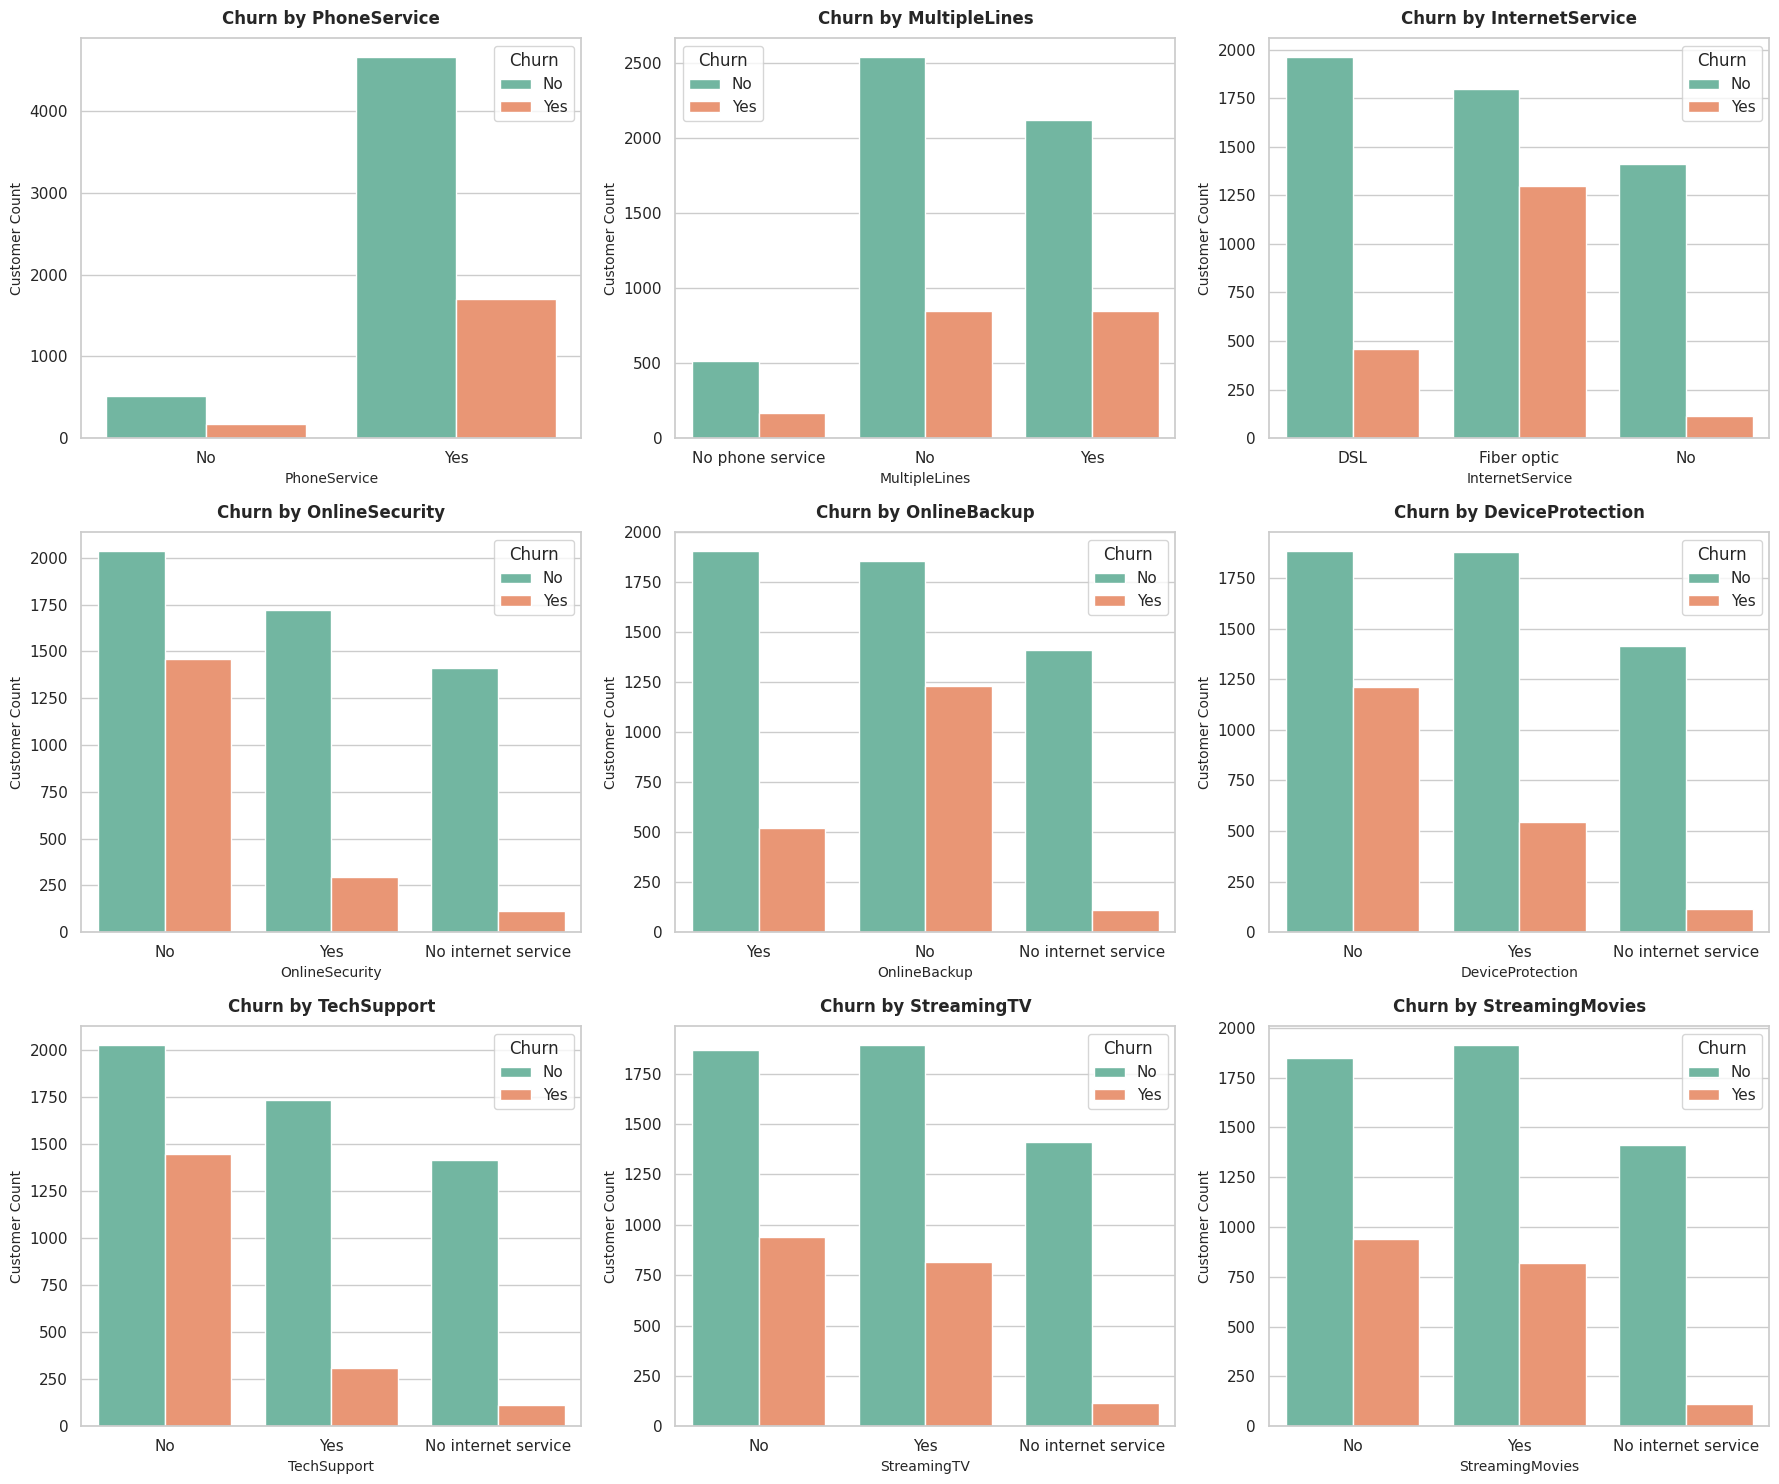

In [ ]:

service_cols = [
    'PhoneService', 'MultipleLines', 'InternetService',
    'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
    'TechSupport', 'StreamingTV', 'StreamingMovies'
]


fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(18, 15))
axes = axes.flatten()

for i, col in enumerate(service_cols):
    sb.countplot(data=df, x=col, hue='Churn', palette='Set2', ax=axes[i])
    axes[i].set_title(f'Churn by {col}', fontsize=12, fontweight='bold', pad=10)
    axes[i].set_xlabel(col, fontsize=10)
    axes[i].set_ylabel('Customer Count', fontsize=10)


plt.tight_layout()
plt.show()


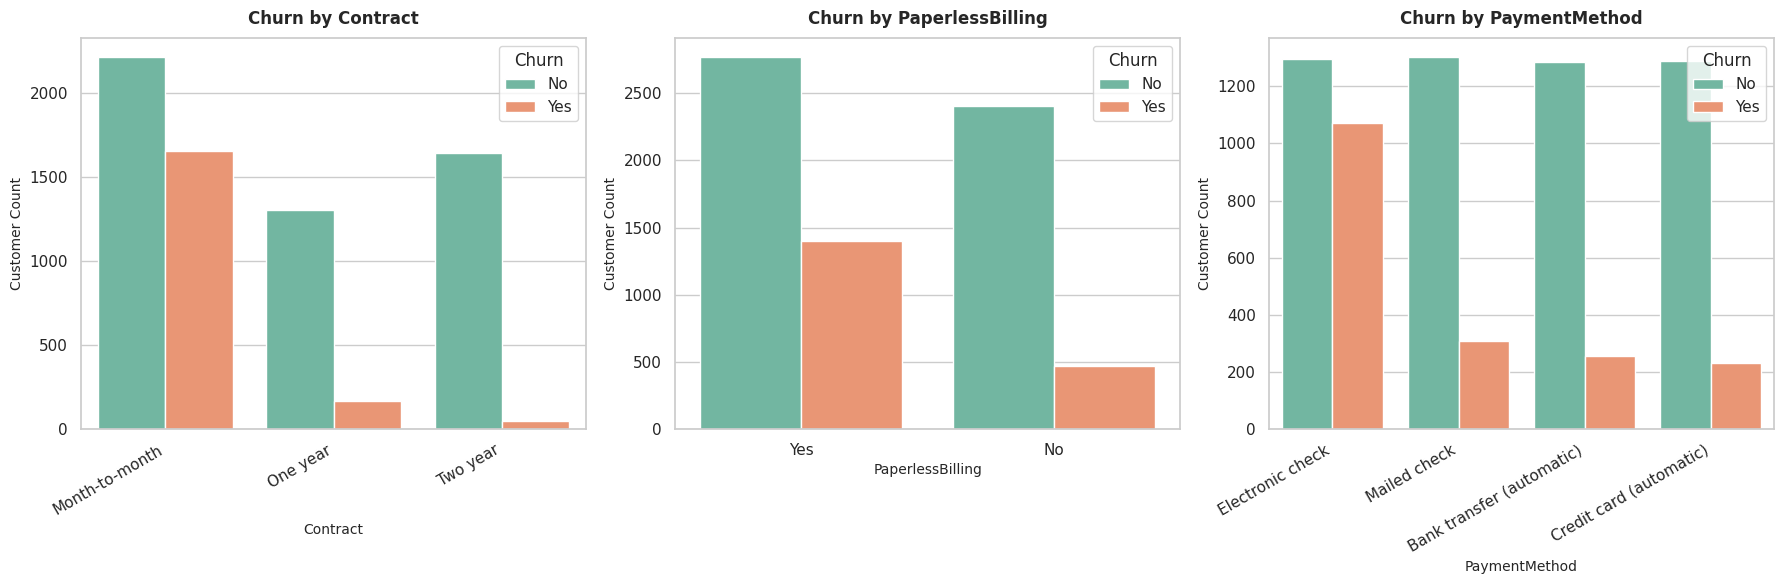

In [ ]:

billing_cols = ['Contract', 'PaperlessBilling', 'PaymentMethod']


fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(18, 6))

for i, col in enumerate(billing_cols):
    sb.countplot(data=df, x=col, hue='Churn', palette='Set2', ax=axes[i])
    axes[i].set_title(f'Churn by {col}', fontsize=12, fontweight='bold', pad=10)
    axes[i].set_xlabel(col, fontsize=10)
    axes[i].set_ylabel('Customer Count', fontsize=10)

    if col == 'PaymentMethod' or col == 'Contract':
        axes[i].tick_params(axis='x', rotation=30)
        plt.setp(axes[i].get_xticklabels(), ha='right')

plt.tight_layout()
plt.show()
